#  Project Insurance Cost Prediction

## 👤 Student Information

| Field           | Entry (fill in)                |
|-----------------|--------------------------------|
| **Name**        | _Ei Htoo Khaing, James Nguyen, Michelle_     |
| **Student #**   | _115400244,  ,_     |
| **Course/Section** |BDA500 NAA    |
| **Date**        | _2026-10-08_                   |


## Dataset: medical_cost_prediction_dataset.csv


## Step 1: Frame Both Questions

• Write one supervised question: What continuous value will the regression models predict?

• Explain the practical value of both analyses and identify likely risks or limitations.

__Supervised Question: How accurately can a patient's annual medical cost (USD) be predicted from demographics, lifestyle habits, and chronic health conditions?__


---


# Step 2: Load and Understand the Data
• Display head (), shape, info (), data types, summary statistics, and missing value counts.  
• Identify numeric, categorical, identifier, date, and potential leakage columns.  
• Document duplicate handling and any rows or columns removed, with reasons.  


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("medical_cost_prediction_dataset.csv")

display(df.head())
print("Shape:", df.shape)
df.info()

,age,gender,bmi,smoker,diabetes,hypertension,heart_disease,asthma,physical_activity_level,daily_steps,sleep_hours,stress_level,doctor_visits_per_year,hospital_admissions,medication_count,insurance_type,insurance_coverage_pct,city_type,previous_year_cost,annual_medical_cost
0,69,Male,29.4,No,1,0,0,0,Medium,14825,4.4,8,1,0,4,Private,80,Semi-Urban,10885,2645.50
1,32,Female,22.9,No,1,0,0,0,Medium,3620,6.0,7,4,3,0,Government,64,Semi-Urban,18722,10959.70
2,89,Male,25.7,No,0,0,0,0,High,10578,4.5,7,2,0,3,NaN,0,Urban,4196,8409.80
3,78,Male,31.9,Yes,0,1,0,0,Low,6226,8.6,9,6,1,7,Government,70,Urban,11128,7996.62
4,38,Male,27.7,No,0,0,0,0,High,6253,5.7,3,6,0,6,Private,77,Urban,15110,3202.52


Shape: (5000, 20)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      5000 non-null   int64  
 1   gender                   5000 non-null   str    
 2   bmi                      5000 non-null   float64
 3   smoker                   5000 non-null   str    
 4   diabetes                 5000 non-null   int64  
 5   hypertension             5000 non-null   int64  
 6   heart_disease            5000 non-null   int64  
 7   asthma                   5000 non-null   int64  
 8   physical_activity_level  5000 non-null   str    
 9   daily_steps              5000 non-null   int64  
 10  sleep_hours              5000 non-null   float64
 11  stress_level             5000 non-null   int64  
 12  doctor_visits_per_year   5000 non-null   int64  
 13  hospital_admissions      5000 non-null   int64  
 14  medication_count 

In [3]:
display(df.describe().T)                    # numeric
display(df.describe(include="str").T)    # categorical

print("Missing values per column:")
print(df.isna().sum())

,count,mean,std,min,25%,50%,75%,max
age,5000.0,53.299000,20.646851,18.00,36.0000,53.00,71.0000,89.0
bmi,5000.0,25.970820,5.046651,6.40,22.6000,25.90,29.4000,43.6
diabetes,5000.0,0.207600,0.405629,0.00,0.0000,0.00,0.0000,1.0
hypertension,5000.0,0.288000,0.452876,0.00,0.0000,0.00,1.0000,1.0
heart_disease,5000.0,0.142200,0.349290,0.00,0.0000,0.00,0.0000,1.0
asthma,5000.0,0.096400,0.295169,0.00,0.0000,0.00,0.0000,1.0
daily_steps,5000.0,7993.216800,4052.127069,1004.00,4545.0000,7989.00,11532.2500,14999.0
sleep_hours,5000.0,6.488140,1.443361,4.00,5.2000,6.50,7.7000,9.0
stress_level,5000.0,5.475400,2.892312,1.00,3.0000,5.00,8.0000,10.0
doctor_visits_per_year,5000.0,4.030600,2.010689,0.00,3.0000,4.00,5.0000,14.0


,count,unique,top,freq
gender,5000,2,Female,2519
smoker,5000,2,No,3779
physical_activity_level,5000,3,Low,1996
insurance_type,3952,2,Private,1979
city_type,5000,3,Urban,2474


Missing values per column:
age                           0
gender                        0
bmi                           0
smoker                        0
diabetes                      0
hypertension                  0
heart_disease                 0
asthma                        0
physical_activity_level       0
daily_steps                   0
sleep_hours                   0
stress_level                  0
doctor_visits_per_year        0
hospital_admissions           0
medication_count              0
insurance_type             1048
insurance_coverage_pct        0
city_type                     0
previous_year_cost            0
annual_medical_cost           0
dtype: int64


• Identify numeric, categorical, identifier, date, and potential leakage columns.  

In [4]:
target = ["annual_medical_cost"] # the target column

leakage_cols = [
    "previous_year_cost",       # last year's cost, copy of target column
    "doctor_visits_per_year",   # utilization happens alongside cost
    "hospital_admissions",
    "medication_count",
    "insurance_type",           # coverage directly reduces final cost
    "insurance_coverage_pct",
]

numeric_cols = [c for c in df.select_dtypes(include="number").columns if c not in leakage_cols + target] # identify numerical columns
categorical_cols = [c for c in df.select_dtypes(include="str").columns if c not in leakage_cols + target] # identify categorical columns

identifier_cols = []   # none in this dataset
date_cols = []         # none in this dataset

print("Target:", target)
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
print("Identifier:", identifier_cols)
print("Date:", date_cols)
print("Potential leakage:", leakage_cols)

Target: ['annual_medical_cost']
Numeric: ['age', 'bmi', 'diabetes', 'hypertension', 'heart_disease', 'asthma', 'daily_steps', 'sleep_hours', 'stress_level']
Categorical: ['gender', 'smoker', 'physical_activity_level', 'city_type']
Identifier: []
Date: []
Potential leakage: ['previous_year_cost', 'doctor_visits_per_year', 'hospital_admissions', 'medication_count', 'insurance_type', 'insurance_coverage_pct']


• Document duplicate handling and any rows or columns removed, with reasons.  

In [5]:
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)

df_clean = df.drop_duplicates().drop(columns=leakage_cols) # drop the duplicates as well as the potential leakage columns
print("Shape before:", df.shape)
print("Shape after:", df_clean.shape)

Duplicate rows: 0
Shape before: (5000, 20)
Shape after: (5000, 14)


### Data Cleaning Notes  
- **Duplicates:** Found 0 duplicate rows.  
- **Missing values:** None found, so no imputation needed.  
- **Identifier and date columns:** None present in this dataset.  
- **Columns removed (6):** previous_year_cost, doctor_visits_per_year, hospital_admissions, medication_count, insurance_type, insurance_coverage_pct.  
  - Reason: these are measured alongside or after healthcare costs happen, or directly change the final cost. Keeping them would leak target information and make the model look more accurate than it would be in real use.  
- **Final shape:** 5000 rows × 14 columns (13 features + target).  

## Step 3: Exploratory Data Analysis  
• Create histograms and boxplots for important numeric features.  
• Create a correlation heatmap for numeric variables.  
• Create at least two plots relating important predictors to the regression target.

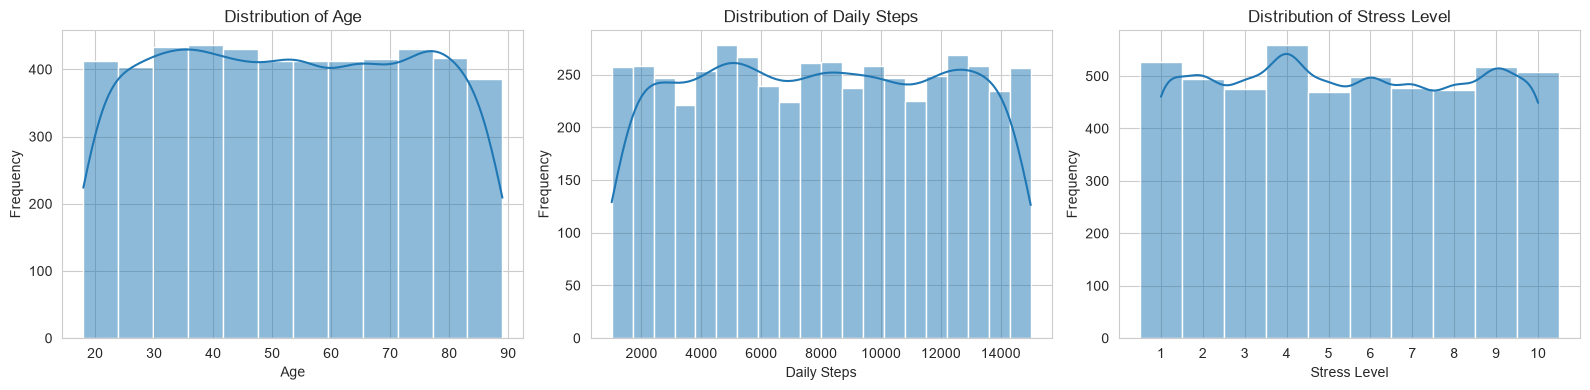

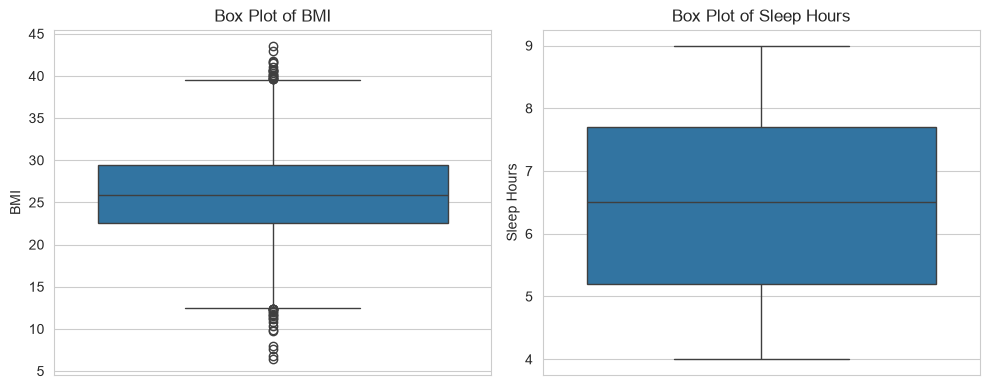

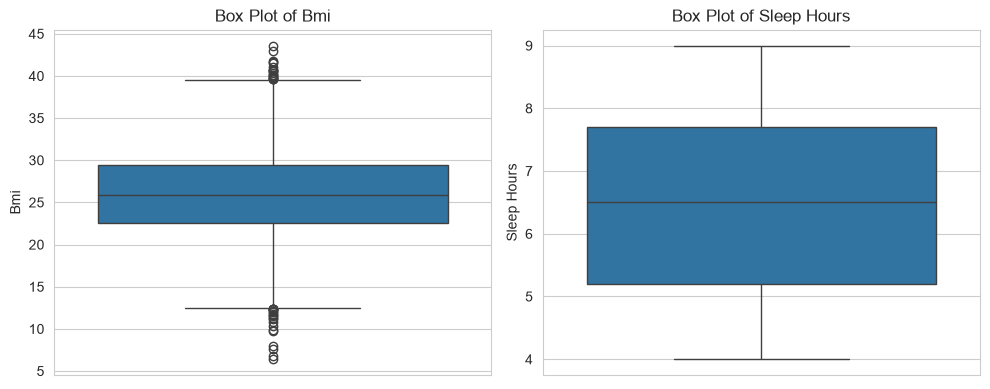

In [6]:
import seaborn as sns

# Set the visual style
sns.set_style("whitegrid")

# 1. Histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Age
sns.histplot(
    data=df, x='age',
    bins=12, kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribution of Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Daily steps
sns.histplot(
    data=df, x='daily_steps',
    bins=20, kde=True,
    ax=axes[1]
)
axes[1].set_title('Distribution of Daily Steps')
axes[1].set_xlabel('Daily Steps')
axes[1].set_ylabel('Frequency')

# Stress level: discrete ratings
sns.histplot(
    data=df, x='stress_level',
    discrete=True,
    kde=True,
    ax=axes[2]
)
axes[2].set_title('Distribution of Stress Level')
axes[2].set_xlabel('Stress Level')
axes[2].set_ylabel('Frequency')
axes[2].set_xticks(range(1, 11))

plt.tight_layout()
plt.show()


# 2. Box plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=df, y='bmi', ax=axes[0])
axes[0].set_title('Box Plot of BMI')
axes[0].set_ylabel('BMI')

sns.boxplot(data=df, y='sleep_hours', ax=axes[1])
axes[1].set_title('Box Plot of Sleep Hours')
axes[1].set_ylabel('Sleep Hours')

plt.tight_layout()
plt.show()


# 2. Box plots
box_columns = ['bmi', 'sleep_hours']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, box_columns):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f'Box Plot of {col.replace("_", " ").title()}')
    ax.set_ylabel(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

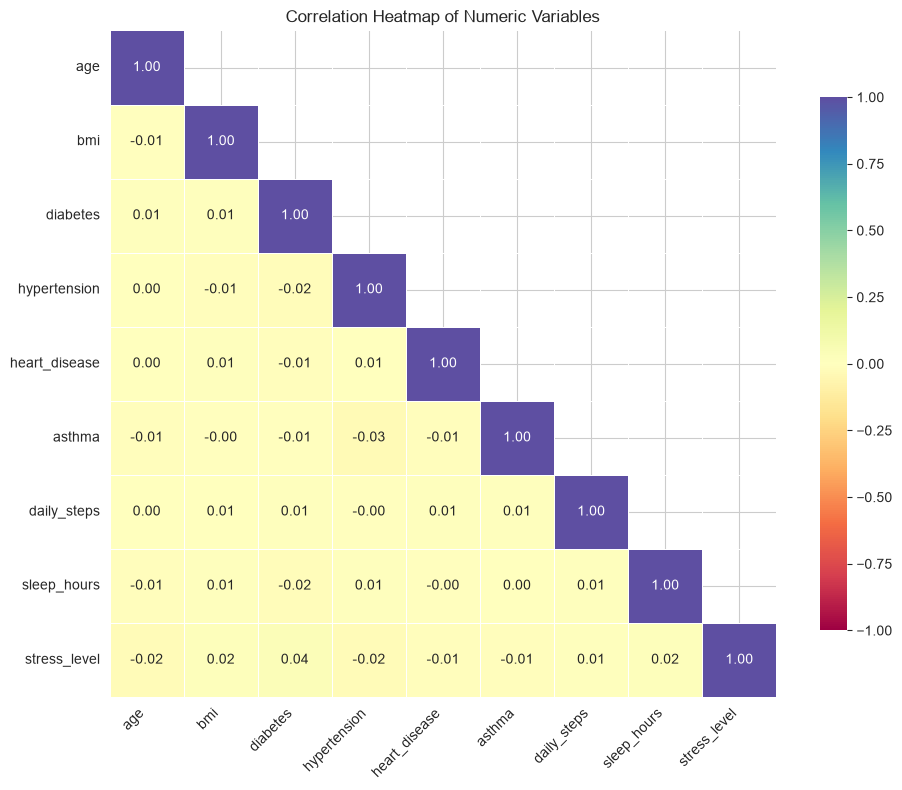

In [7]:
# Calculate the correlation matrix
corr_matrix = df[numeric_cols].corr()

# Mask the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='Spectral',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Correlation Heatmap of Numeric Variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

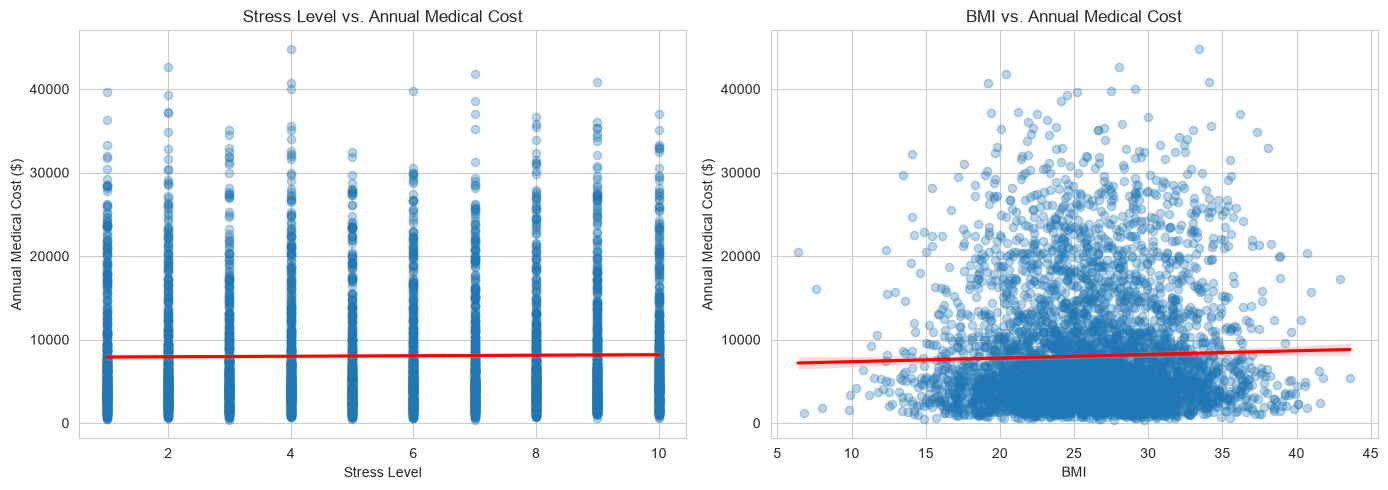

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stress level vs. annual medical cost
sns.regplot(
    data=df,
    x='stress_level',
    y='annual_medical_cost',
    ax=axes[0],
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

axes[0].set_title('Stress Level vs. Annual Medical Cost')
axes[0].set_xlabel('Stress Level')
axes[0].set_ylabel('Annual Medical Cost ($)')

# BMI vs. annual medical cost
sns.regplot(
    data=df,
    x='bmi',
    y='annual_medical_cost',
    ax=axes[1],
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

axes[1].set_title('BMI vs. Annual Medical Cost')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Annual Medical Cost ($)')

plt.tight_layout()
plt.show()

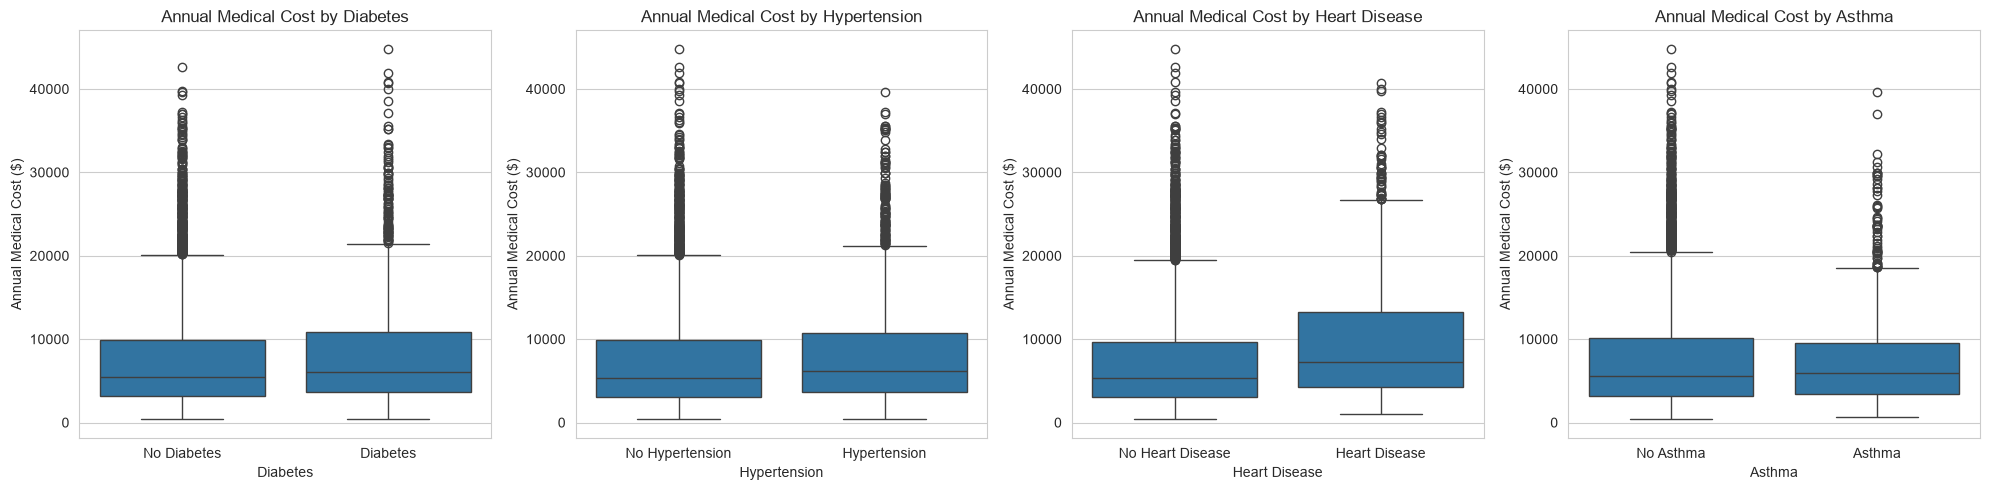

In [ ]:
features = ['diabetes', 'hypertension', 'heart_disease', 'asthma']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
labels = {
    'diabetes': ['No Diabetes', 'Diabetes'],
    'hypertension': ['No Hypertension', 'Hypertension'],
    'heart_disease': ['No Heart Disease', 'Heart Disease'],
    'asthma': ['No Asthma', 'Asthma']
}

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x=feature,
        y='annual_medical_cost',
        ax=ax
    )

    ax.set_title(f'Annual Medical Cost by {feature.replace("_", " ").title()}')
    ax.set_xlabel(feature.replace('_', ' ').title())
    ax.set_ylabel('Annual Medical Cost ($)')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels[feature])

plt.tight_layout()
plt.show()

## Step 4: Prepare Features  
• Handle missing values using a justified strategy.  
• Encode categorical variables using OneHotEncoder or justified ordinal encoding.  
• Scale numeric features using StandardScaler or justify MinMaxScaler..

In [16]:
from sklearn.preprocessing import OneHotEncoder

categorical = [
    'gender',
    'smoker',
    'physical_activity_level',
    'city_type'
]

# Define the expected categories and their order
categories = [
    ['Male', 'Female'],
    ['Yes', 'No'],
    ['Low', 'Medium', 'High'],
    ['Urban', 'Semi-urban', 'Rural']
]

# Initialize the encoder
encoder = OneHotEncoder(
    categories=categories,
    handle_unknown='ignore',
    sparse_output=False
)

# Fit and transform categorical columns
encoded_array = encoder.fit_transform(df[categorical])

# Create a DataFrame with encoded column names
encoded_columns = encoder.get_feature_names_out(categorical)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=df.index
)

# Replace original categorical columns with encoded columns
df = pd.concat(
    [df.drop(columns=categorical), encoded_df],
    axis=1
)

print(df.head())
print(df.columns.tolist())

   age   bmi  diabetes  hypertension  heart_disease  asthma  daily_steps  \
0   69  29.4         1             0              0       0        14825   
1   32  22.9         1             0              0       0         3620   
2   89  25.7         0             0              0       0        10578   
3   78  31.9         0             1              0       0         6226   
4   38  27.7         0             0              0       0         6253   

   sleep_hours  stress_level  doctor_visits_per_year  ...  gender_Male  \
0          4.4             8                       1  ...          1.0   
1          6.0             7                       4  ...          0.0   
2          4.5             7                       2  ...          1.0   
3          8.6             9                       6  ...          1.0   
4          5.7             3                       6  ...          1.0   

   gender_Female smoker_Yes  smoker_No  physical_activity_level_Low  \
0            0.0        0.0

In [17]:
from sklearn.preprocessing import StandardScaler

# Continuous numeric predictors
numeric_features = [
    'age',
    'bmi',
    'daily_steps',
    'sleep_hours',
    'stress_level'
]
# Initialize scaler
scaler = StandardScaler()

# Scale continuous features
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# Verify the scaling
print("Scaled feature means:")
print(df[numeric_features].mean().round(3))

print("\nScaled feature standard deviations:")
print(df[numeric_features].std().round(3))

print("\nScaled data preview:")
print(df[numeric_features].head())

Scaled feature means:
age             0.0
bmi             0.0
daily_steps    -0.0
sleep_hours     0.0
stress_level    0.0
dtype: float64

Scaled feature standard deviations:
age             1.0
bmi             1.0
daily_steps     1.0
sleep_hours     1.0
stress_level    1.0
dtype: float64

Scaled data preview:
        age       bmi  daily_steps  sleep_hours  stress_level
0  0.760531  0.679564     1.686143    -1.446866      0.872953
1 -1.031689 -0.608548    -1.079348    -0.338231      0.527174
2  1.729299 -0.053669     0.637947    -1.377576      0.527174
3  1.196476  1.174992    -0.436164     1.463301      1.218732
4 -0.741059  0.342673    -0.429501    -0.546100     -0.855941


## Step 5: Build Configuration  
• Use ColumnTransformer to combine numeric and categorical preprocessing.  
• Create train/test split, recommended test % given in the table below.  
• Fit regression preprocessing only on the training data, then transform validation or test data without refitting.  
• Use cross-validation numbers given in the table below on the training data for comparison and tuning.

In [23]:
print(df.columns.tolist())
print(df.head())

['age', 'bmi', 'diabetes', 'hypertension', 'heart_disease', 'asthma', 'daily_steps', 'sleep_hours', 'stress_level', 'doctor_visits_per_year', 'hospital_admissions', 'medication_count', 'insurance_type', 'insurance_coverage_pct', 'previous_year_cost', 'annual_medical_cost', 'gender_Male', 'gender_Female', 'smoker_Yes', 'smoker_No', 'physical_activity_level_Low', 'physical_activity_level_Medium', 'physical_activity_level_High', 'city_type_Urban', 'city_type_Semi-urban', 'city_type_Rural']
        age       bmi  diabetes  hypertension  heart_disease  asthma  \
0  0.760531  0.679564         1             0              0       0   
1 -1.031689 -0.608548         1             0              0       0   
2  1.729299 -0.053669         0             0              0       0   
3  1.196476  1.174992         0             1              0       0   
4 -0.741059  0.342673         0             0              0       0   

   daily_steps  sleep_hours  stress_level  doctor_visits_per_year  ...  \
0

In [24]:

# Check whether your original categorical columns still exist
original_categorical_cols = [
    "gender",
    "smoker",
    "physical_activity_level",
    "city_type"
]

for col in original_categorical_cols:
    print(f"{col}: {col in df.columns}")

gender: False
smoker: False
physical_activity_level: False
city_type: False


In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Existing numeric columns (already scaled)
numeric_cols = [
    "age", "bmi", "diabetes", "hypertension",
    "heart_disease", "asthma", "daily_steps",
    "sleep_hours", "stress_level"
]

# Existing one-hot-encoded categorical columns
categorical_encoded_cols = [
    col for col in df.columns
    if col.startswith((
        "gender_",
        "smoker_",
        "physical_activity_level_",
        "city_type_"
    ))
]

# Define X and y from the current dataframe
X = df[numeric_cols + categorical_encoded_cols].copy()
y = df[target].copy()

# ColumnTransformer combines the two existing feature groups.
preproc = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
    ("cat", "passthrough", categorical_encoded_cols)
])

model = Pipeline([
    ("preprocessor", preproc),
    ("regressor", LinearRegression())
])
models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preproc),
        ('regressor', LinearRegression())
    ]),

    'Ridge Regression': Pipeline([
        ('preprocessor', preproc),
        ('regressor', Ridge(alpha=1.0))
    ]),

    'Polynomial Regression': Pipeline([
        ('preprocessor', preproc),
        ('polynomial', PolynomialFeatures(
            degree=3,
            include_bias=False
        )),
        ('regressor', LinearRegression())
    ])
}

In [36]:
test_size = 0.10
random_states = [0, 42]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

cv_results = []
test_results = []

for model_name, model in models.items():
    for rs in random_states:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=rs
        )
        # Five-fold cross-validation on training data only
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )
        cv_results.append({
            'Model': model_name,
            'Test Size': test_size,
            'Random State': rs,
            'CV MAE Mean': - scores['test_mae'].mean(),
            'CV MAE Std': scores['test_mae'].std(ddof=1),
            'CV RMSE Mean': - scores['test_rmse'].mean(),
            'CV RMSE Std': scores['test_rmse'].std(ddof=1),
            'CV R2 Mean': scores['test_r2'].mean(),
            'CV R2 Std': scores['test_r2'].std(ddof=1)
        })

        # Fit on the full training split, then evaluate on held-out test data
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        test_results.append({
            'Model': model_name,
            'Test Size': test_size,
            'Random State': rs,
            'Test MAE': mean_absolute_error(y_test, y_pred),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
            'Test R2': r2_score(y_test, y_pred)
        })

cv_summary = pd.DataFrame(cv_results)
test_summary = pd.DataFrame(test_results)

print("CROSS-VALIDATION RESULTS")
display(cv_summary.round(4))

print("TEST SET RESULTS")
display(test_summary.round(4))

CROSS-VALIDATION RESULTS


,Model,Test Size,Random State,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,Linear Regression,0.1,0,5311.1935,170.7054,7069.4703,271.8080,0.0123,0.0213
1,Linear Regression,0.1,42,5250.2874,178.9026,7008.1660,239.4852,0.0199,0.0106
2,Ridge Regression,0.1,0,5311.1383,170.7940,7069.4183,271.9089,0.0123,0.0212
3,Ridge Regression,0.1,42,5250.2405,178.8302,7008.1337,239.4737,0.0199,0.0105
4,Polynomial Regression,0.1,0,5875.7316,209.1139,7859.0474,362.2561,-0.2210,0.0600
5,Polynomial Regression,0.1,42,5858.4078,204.3572,7903.6888,242.5240,-0.2474,0.0443


TEST SET RESULTS


,Model,Test Size,Random State,Test MAE,Test RMSE,Test R2
0,Linear Regression,0.1,0,4931.6914,6458.2725,0.0179
1,Linear Regression,0.1,42,5276.6173,6918.3449,0.0098
2,Ridge Regression,0.1,0,4931.6836,6458.2500,0.0179
3,Ridge Regression,0.1,42,5276.6049,6918.3245,0.0098
4,Polynomial Regression,0.1,0,5366.7850,7104.6354,-0.1885
5,Polynomial Regression,0.1,42,5438.5817,7237.5862,-0.0837
